# 04 — Análise para Classificação

Este notebook apresenta a análise do problema de classificação definido para o conjunto de dados de baterias de veículos elétricos.

A variável `battery_failure` foi selecionada como alvo, representando a ausência (0) ou ocorrência (1) de falha da bateria. A análise investiga o desbalanceamento das classes, as relações com variáveis numéricas e categóricas e as características com maior potencial preditivo.

In [ ]:
import os
import pandas as pd

caminho = "/content/ev_battery_failure_dataset.csv"

print("Tamanho do arquivo (bytes):", os.path.getsize(caminho))

df = pd.read_csv(caminho)

print("Dimensões:", df.shape)
print("IDs únicos:", df['vehicle_id'].nunique())
print("Primeiro ID:", df['vehicle_id'].iloc[0])
print("Último ID:", df['vehicle_id'].iloc[-1])

Tamanho do arquivo (bytes): 77211206
Dimensões: (200000, 70)
IDs únicos: 200000
Primeiro ID: EV100000
Último ID: EV299999


## Definição do problema de classificação

O alvo escolhido foi `battery_failure`, uma variável binária que representa diretamente a ocorrência de falha da bateria.

Os identificadores `vehicle_id` e `battery_serial` foram removidos por não representarem características preditivas relevantes para o problema.

In [ ]:
# Alvo da classificação
target_class = 'battery_failure'

# Remover identificadores
df_class = df.drop(columns=['vehicle_id', 'battery_serial']).copy()

print("Dimensões do dataset de classificação:", df_class.shape)
print("Alvo:", target_class)

Dimensões do dataset de classificação: (200000, 68)
Alvo: battery_failure


## Distribuição das classes

Antes da análise das características, foi verificada a distribuição da variável-alvo para identificar possível desbalanceamento entre as classes.

In [ ]:
# Distribuição das classes
class_counts = df_class[target_class].value_counts().sort_index()
class_percent = df_class[target_class].value_counts(
    normalize=True
).sort_index() * 100

print("Quantidade por classe:")
print(class_counts)

print("\nPercentual por classe:")
print(class_percent)

Quantidade por classe:
battery_failure
0    180079
1     19921
Name: count, dtype: int64

Percentual por classe:
battery_failure
0    90.0395
1     9.9605
Name: proportion, dtype: float64


A distribuição apresenta forte desbalanceamento: aproximadamente **90,04%** dos registros pertencem à classe 0, correspondente à ausência de falha, enquanto **9,96%** pertencem à classe 1, correspondente à ocorrência de falha.

Esse comportamento deve ser considerado posteriormente na escolha das métricas de avaliação e dos algoritmos de classificação.

## Relação das variáveis numéricas com a falha

A correlação das variáveis numéricas com `battery_failure` foi utilizada como uma análise inicial para identificar características associadas à ocorrência de falha.

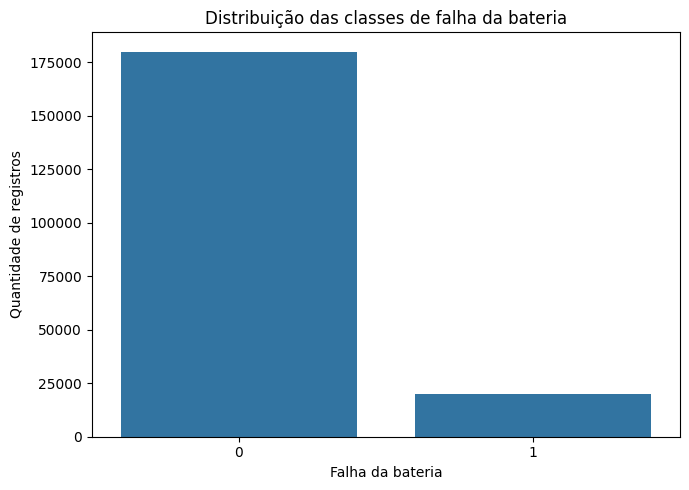

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_class,
    x=target_class
)

plt.xlabel('Falha da bateria')
plt.ylabel('Quantidade de registros')
plt.title('Distribuição das classes de falha da bateria')

plt.tight_layout()
plt.show()

In [ ]:
# Correlação das variáveis numéricas com o alvo de classificação

numeric_class = df_class.select_dtypes(include=np.number)

corr_failure = (
    numeric_class.corr()['battery_failure']
    .drop('battery_failure')
    .sort_values(key=abs, ascending=False)
)

corr_failure.head(15)

,battery_failure
capacity_loss_percent,0.638552
battery_health_percent,-0.637646
state_of_health,-0.635753
aging_score,0.598189
cell_voltage_std,0.590070
charge_efficiency,-0.524607
cycle_count,0.517557
odometer_km,0.509988
voltage_imbalance,0.496980
charging_quality_score,-0.421923


As maiores associações positivas foram observadas para `capacity_loss_percent` (r = 0,639), `aging_score` (r = 0,598) e `cell_voltage_std` (r = 0,590).

Entre as correlações negativas, destacam-se `battery_health_percent` (r = -0,638), `state_of_health` (r = -0,636) e `charge_efficiency` (r = -0,525).

Esses resultados sugerem que características relacionadas à degradação, saúde e estabilidade elétrica da bateria apresentam potencial relevante para o problema de classificação.

## Comparação das características entre as classes

As cinco variáveis numéricas com maior associação com `battery_failure` foram analisadas por meio de boxplots, permitindo comparar suas distribuições entre os registros com e sem falha.

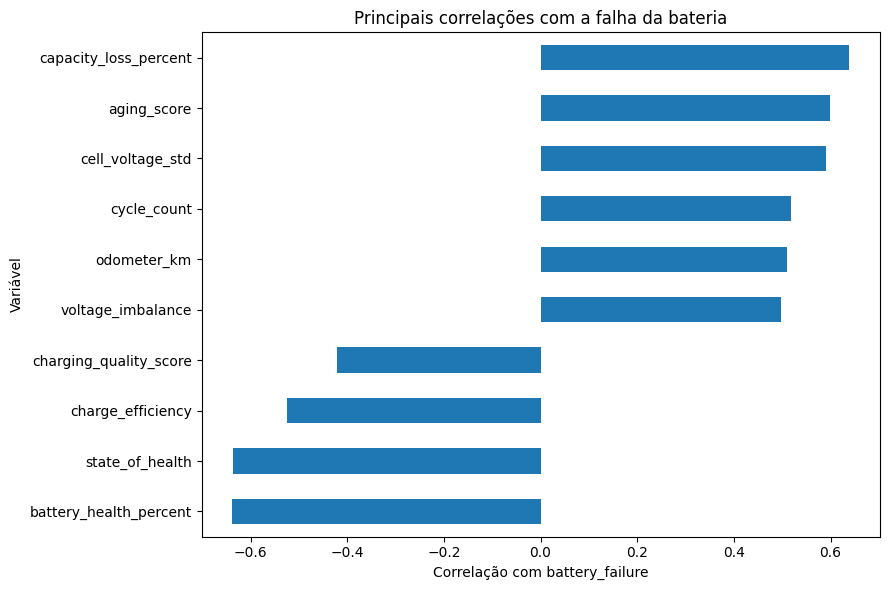

In [ ]:
# Visualização das principais correlações com battery_failure

top_corr = corr_failure.head(10).sort_values()

plt.figure(figsize=(9, 6))

top_corr.plot(kind='barh')

plt.xlabel('Correlação com battery_failure')
plt.ylabel('Variável')
plt.title('Principais correlações com a falha da bateria')

plt.tight_layout()
plt.show()

Os gráficos mostram diferenças claras entre as duas classes. Registros com falha apresentam, de forma geral, maior perda de capacidade, maior índice de envelhecimento e maior variabilidade da tensão das células, enquanto indicadores de saúde da bateria apresentam valores inferiores.

## Teste ANOVA

O teste ANOVA foi aplicado às principais características numéricas para avaliar se as diferenças observadas entre as classes são estatisticamente significativas.

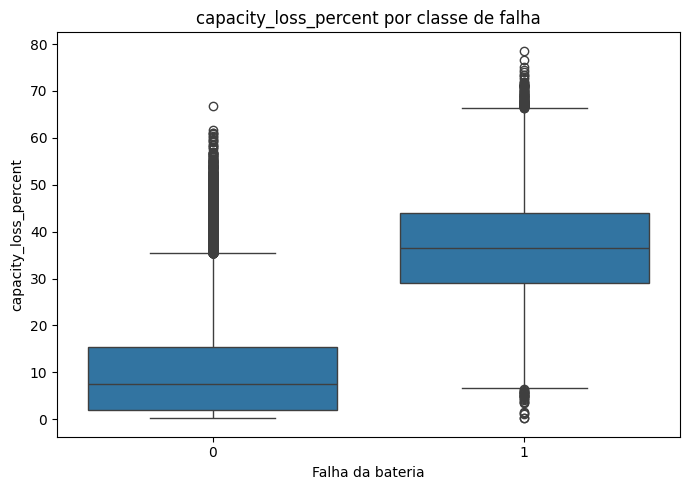

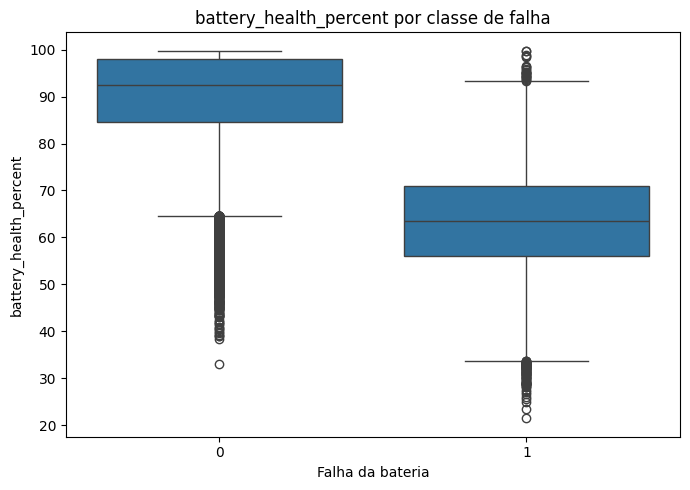

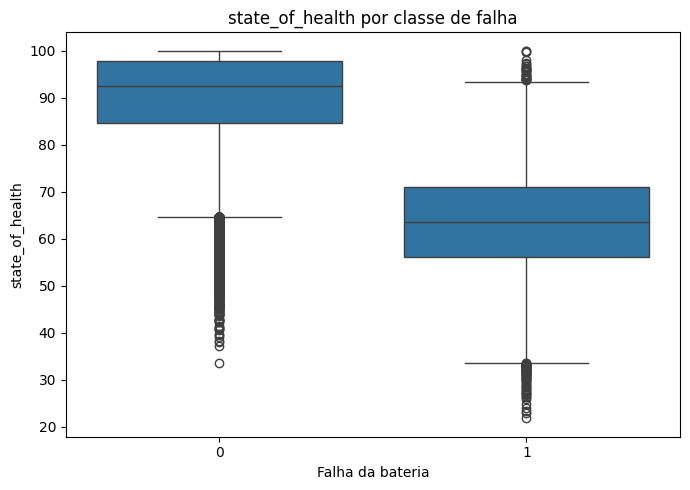

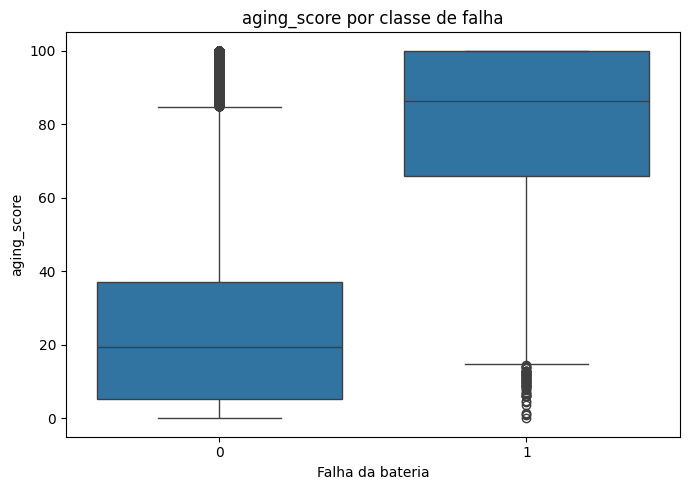

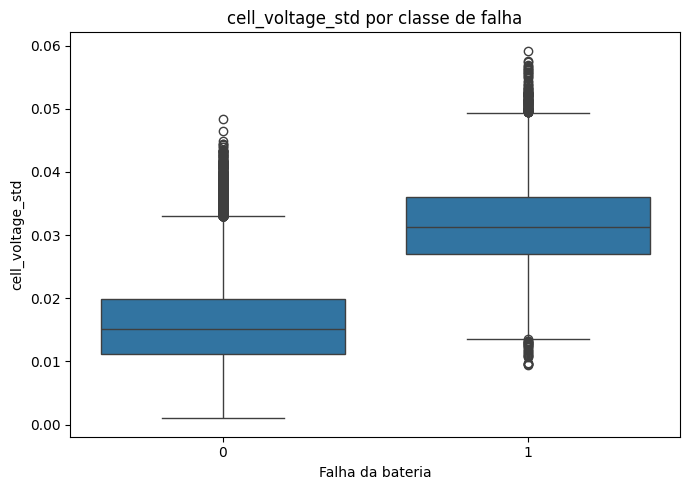

In [ ]:
features_boxplot = [
    'capacity_loss_percent',
    'battery_health_percent',
    'state_of_health',
    'aging_score',
    'cell_voltage_std'
]

for feature in features_boxplot:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df_class,
        x='battery_failure',
        y=feature
    )

    plt.xlabel('Falha da bateria')
    plt.ylabel(feature)
    plt.title(f'{feature} por classe de falha')

    plt.tight_layout()
    plt.show()

Todas as cinco características analisadas apresentaram diferenças estatisticamente significativas entre as classes (p < 0,001).

Os maiores valores da estatística F foram observados para `capacity_loss_percent`, `battery_health_percent` e `state_of_health`, reforçando as evidências encontradas nas correlações e nos boxplots.

## Associação das variáveis categóricas com a falha

Para as variáveis categóricas, foi aplicado o teste qui-quadrado de independência com o objetivo de verificar a existência de associação estatística com `battery_failure`.

In [ ]:
from scipy.stats import f_oneway

features_anova = [
    'capacity_loss_percent',
    'battery_health_percent',
    'state_of_health',
    'aging_score',
    'cell_voltage_std'
]

anova_results = []

for feature in features_anova:
    grupo_0 = df_class.loc[
        df_class['battery_failure'] == 0, feature
    ].dropna()

    grupo_1 = df_class.loc[
        df_class['battery_failure'] == 1, feature
    ].dropna()

    estatistica, p_valor = f_oneway(grupo_0, grupo_1)

    anova_results.append({
        'variavel': feature,
        'estatistica_F': estatistica,
        'p_valor': p_valor
    })

anova_df = pd.DataFrame(anova_results)

anova_df.sort_values(
    'estatistica_F',
    ascending=False
)

,variavel,estatistica_F,p_valor
0,capacity_loss_percent,131111.709753,0.0
1,battery_health_percent,130881.045788,0.0
2,state_of_health,129182.667105,0.0
3,aging_score,106781.607402,0.0
4,cell_voltage_std,102259.349130,0.0


Foram identificadas associações estatisticamente significativas (p < 0,001) para `fleet_or_private`, `battery_chemistry`, `vehicle_brand`, `vehicle_model` e `vehicle_type`.

Por outro lado, `battery_manufacturer`, `drive_type` e `terrain_type` não apresentaram associação estatisticamente significativa com a ocorrência de falha.

Como o conjunto possui 200.000 registros, os resultados de significância estatística devem ser interpretados com cautela, pois significância não implica necessariamente grande efeito preditivo.

## Tipo de utilização e ocorrência de falhas

Como `fleet_or_private` apresentou forte associação com a variável-alvo no teste qui-quadrado, foi analisada a taxa de falha separadamente para veículos de frota e veículos particulares.

In [ ]:
from scipy.stats import chi2_contingency

categorical_features = [
    'vehicle_brand',
    'vehicle_model',
    'vehicle_type',
    'battery_manufacturer',
    'battery_chemistry',
    'drive_type',
    'fleet_or_private',
    'terrain_type'
]

chi_results = []

for feature in categorical_features:
    tabela = pd.crosstab(
        df_class[feature],
        df_class['battery_failure']
    )

    qui2, p_valor, graus_liberdade, esperados = chi2_contingency(tabela)

    chi_results.append({
        'variavel': feature,
        'qui2': qui2,
        'graus_liberdade': graus_liberdade,
        'p_valor': p_valor
    })

chi_df = pd.DataFrame(chi_results)

chi_df.sort_values(
    'p_valor'
)

,variavel,qui2,graus_liberdade,p_valor
0,vehicle_brand,3425.924765,19,0.000000
1,vehicle_model,3415.830917,54,0.000000
2,vehicle_type,1637.647851,5,0.000000
4,battery_chemistry,7719.855921,4,0.000000
6,fleet_or_private,22123.001503,1,0.000000
3,battery_manufacturer,6.227866,8,0.621724
5,drive_type,0.568222,2,0.752683
7,terrain_type,1.258744,4,0.868335


In [ ]:
# Taxa de falha por tipo de utilização

failure_by_fleet = (
    df_class.groupby('fleet_or_private')['battery_failure']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

failure_by_fleet

,battery_failure
fleet_or_private,
Fleet,26.291825
Private,3.600969


Veículos classificados como `Fleet` apresentaram taxa de falha de aproximadamente **26,29%**, enquanto veículos `Private` apresentaram taxa de aproximadamente **3,60%**.

Essa diferença reforça a relevância de `fleet_or_private` como característica potencialmente útil para a classificação.

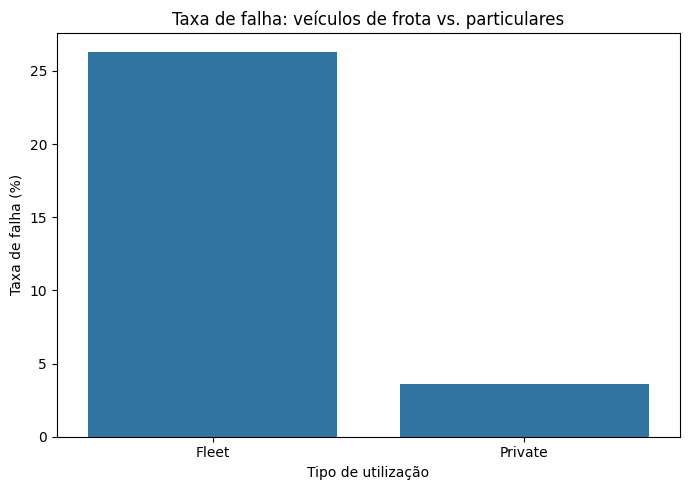

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=failure_by_fleet.index,
    y=failure_by_fleet.values
)

plt.xlabel('Tipo de utilização')
plt.ylabel('Taxa de falha (%)')
plt.title('Taxa de falha: veículos de frota vs. particulares')

plt.tight_layout()
plt.show()

## Conclusões da análise de classificação

A variável `battery_failure` apresentou forte desbalanceamento, com aproximadamente 90% dos registros pertencentes à classe sem falha e 10% à classe com falha.

Entre as características numéricas, destacaram-se `capacity_loss_percent`, `battery_health_percent`, `state_of_health`, `aging_score`, `cell_voltage_std`, `charge_efficiency`, `cycle_count`, `odometer_km` e `voltage_imbalance`. Os boxplots e testes ANOVA confirmaram diferenças significativas entre as classes para as principais características analisadas.

Entre as características categóricas, `fleet_or_private`, `battery_chemistry`, `vehicle_brand`, `vehicle_model` e `vehicle_type` apresentaram associação estatisticamente significativa com a ocorrência de falha.

Um dos principais desafios para a modelagem será o desbalanceamento das classes. Por esse motivo, a avaliação dos modelos não deve se limitar à acurácia, sendo recomendadas métricas como **precision, recall, F1-score e ROC-AUC**, com atenção especial ao recall da classe de falha.

Algoritmos como **Regressão Logística**, **Random Forest** e métodos de **Gradient Boosting** são candidatos adequados para comparação no problema de classificação.